## Анализ и прогнозирование временных рядов методами искусственного интеллекта

### **Практическая работа 3. Поиск аномалий во временных рядах.**


#### **3.1 Поиск диссонансов с помощью алгоритма HotSAX**

##### 3.1.1 Загрузка и подготовка данных

В данной будет использоваться временной ряд, состоящий из показаний акселерометра. 
Анализируемый временной ряд, описывает две активности человека - бег и шаг.


In [1]:
!pip install scipy
!pip install scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from time import time
import pandas as pd

In [3]:
#fixme: Путь
dataset_dir_path = Path('datasets')
data_path = dataset_dir_path/'walk_run.txt'
walk_run = np.loadtxt(data_path)[3000:4000]
data = walk_run
size_sub = 50

В середине временного ряда происходит смена активности (бег заменяет шаг). Нетипичным поведением, которое мы могли бы назвать диссонансами в данном ряде выступает небольшой участок между активностями, когда человек плавно увеличивает скорость шага до бега. В ходе данной работе наша задача выделить с помощью различных алгоритмов границы нашего диссонанса.

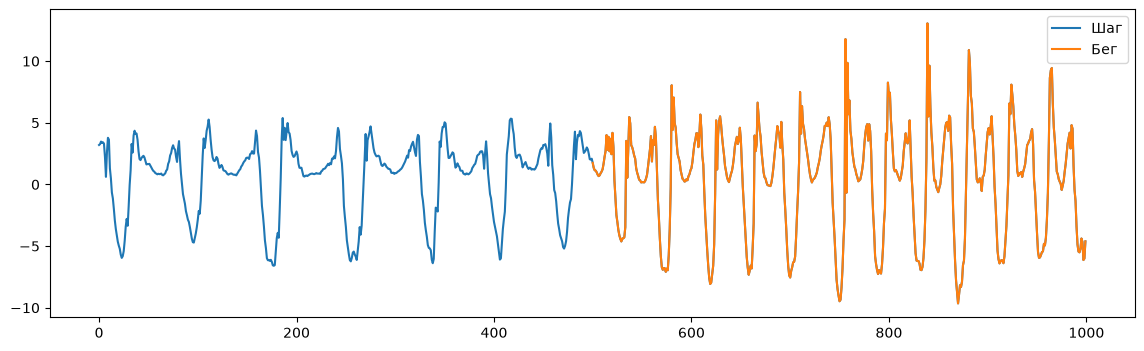

In [4]:
fig, ax =  plt.subplots(figsize=(14,4),ncols=1,nrows=1)
plt.plot(data[:],label='Шаг')
plt.plot(np.arange(data.shape[0]//2,data.shape[0]),data[data.shape[0]//2:],label='Бег')
plt.legend()

In [5]:
result={}
times={}

##### 3.1.2 Реализация полного перебора

Приводится пример кода для нахождения топ 5 диссонансов с помощью реализации полного беребора.
Вам необходимо добавить код для сбора времени обработки данных.

In [5]:
from modules.saxpy.discord import find_discords_brute_force
start = time()
discords_brute_force= np.stack(find_discords_brute_force(data[:], 50, 5))
end = time()

execution_time = end - start
times['brute_force'] = execution_time
print(f"Время выполнения brute force: {execution_time:.2f} секунд")

Время выполнения brute force: 110.23 секунд


##### 3.1.3 HotSAX

Используя [реализацию](https://github.com/seninp/saxpy/blob/master/saxpy/hotsax.py) найдите топ 5 диссонансов ряда.
Произведите замер времени работы.

In [6]:
# INSERT YOUR CODE

from modules.saxpy.hotsax import find_discords_hotsax
start = time()
discords_hotsax= np.stack(find_discords_hotsax(data[:], 50, 5))
end = time()

execution_time = end - start
times['hotsax'] = execution_time
print(f"Время выполнения hotsax: {execution_time:.2f} секунд")

Время выполнения hotsax: 5.25 секунд


##### 3.1.4 Визаулизация

Вам необходимо реализовать код позволяющий:
1. Вывести на одном графике ряд и его диссонансы
2. Столбчатую диаграмму времени работы обоих алгоритмов
   
Постройте графики для обоих алгоритмов и сравните полученные результаты.

Пример графика:

![first_graf](pics/fig_ex_1.png)

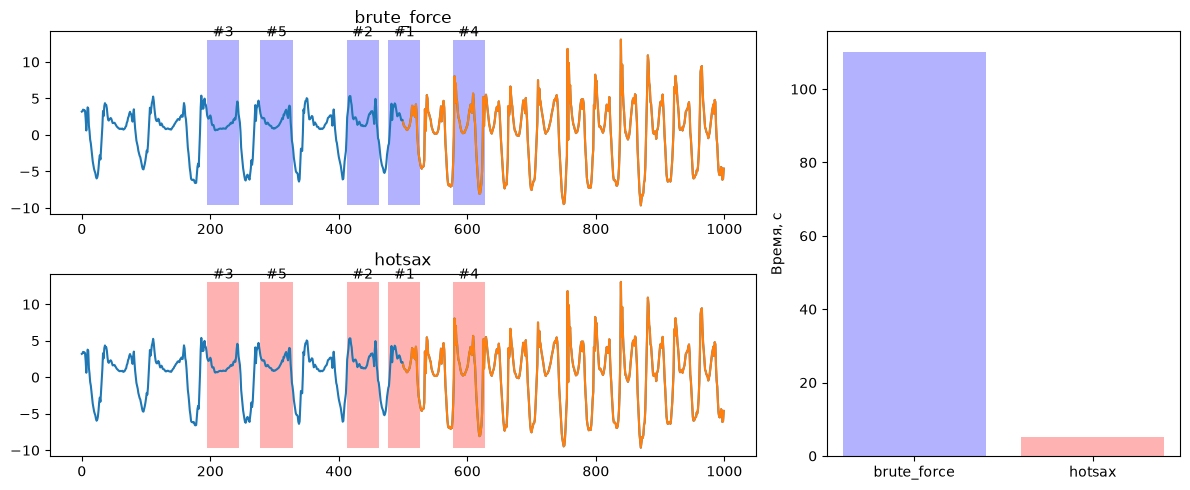

In [7]:
from matplotlib.patches import Rectangle

fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(2, 2, width_ratios=[2, 1])

ax_bf = fig.add_subplot(gs[0, 0])
ax_hs = fig.add_subplot(gs[1, 0])
ax_time = fig.add_subplot(gs[:, 1])

ax_bf.plot(data, color='tab:blue', label='Шаг')
ax_bf.plot(np.arange(data.shape[0]//2, data.shape[0]), data[data.shape[0]//2:], color='tab:orange', label='Бег')
ax_bf.set_title('brute_force')

for i, discord in enumerate(discords_brute_force):
    start_idx = int(discord[0])
    rect = Rectangle((start_idx, np.min(data)), size_sub, np.max(data) - np.min(data), 
                     facecolor='blue', alpha=0.3, edgecolor='none')
    ax_bf.add_patch(rect)
    # номер диссонанса
    ax_bf.text(start_idx + size_sub/2, np.max(data), f'#{i+1}', ha='center', va='bottom', fontsize=10)

ax_hs.plot(data, color='tab:blue', label='Шаг')
ax_hs.plot(np.arange(data.shape[0]//2, data.shape[0]), data[data.shape[0]//2:], color='tab:orange', label='Бег')
ax_hs.set_title('hotsax')

for i, discord in enumerate(discords_hotsax):
    start_idx = int(discord[0])
    rect = Rectangle((start_idx, np.min(data)), size_sub, np.max(data) - np.min(data), 
                     facecolor='red', alpha=0.3, edgecolor='none')
    ax_hs.add_patch(rect)
    ax_hs.text(start_idx + size_sub/2, np.max(data), f'#{i+1}', ha='center', va='bottom', fontsize=10)

algorithms = ['brute_force', 'hotsax']
execution_times = [times['brute_force'], times['hotsax']]

bars = ax_time.bar(algorithms, execution_times, color=['blue', 'red'], alpha=0.3)

ax_time.set_ylabel('Время, с')

plt.tight_layout()
plt.show()

##### 3.1.5 Такси NY

Произведите поиск диссонансов с помощью обоих алгоритмов на наборе данных, содержащим информацию о среднем числе пассажиров в NY. Отобразите найденные диссонансы обоими алгоритмами. 

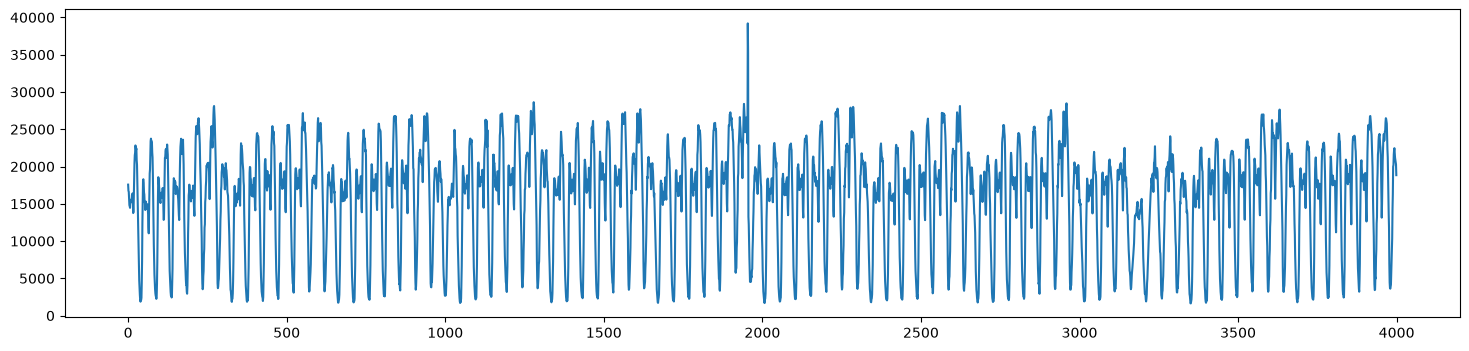

In [6]:
nyc_taxi = pd.read_csv(dataset_dir_path/'nyc_taxi.csv',index_col=0).values[4000:8000,0].astype(np.float64)
fig = plt.figure(figsize=(18, 4))
plt.plot(nyc_taxi)

Время brute force для такси: 1430.64 секунд
Время hotsax для такси: 4.94 секунд


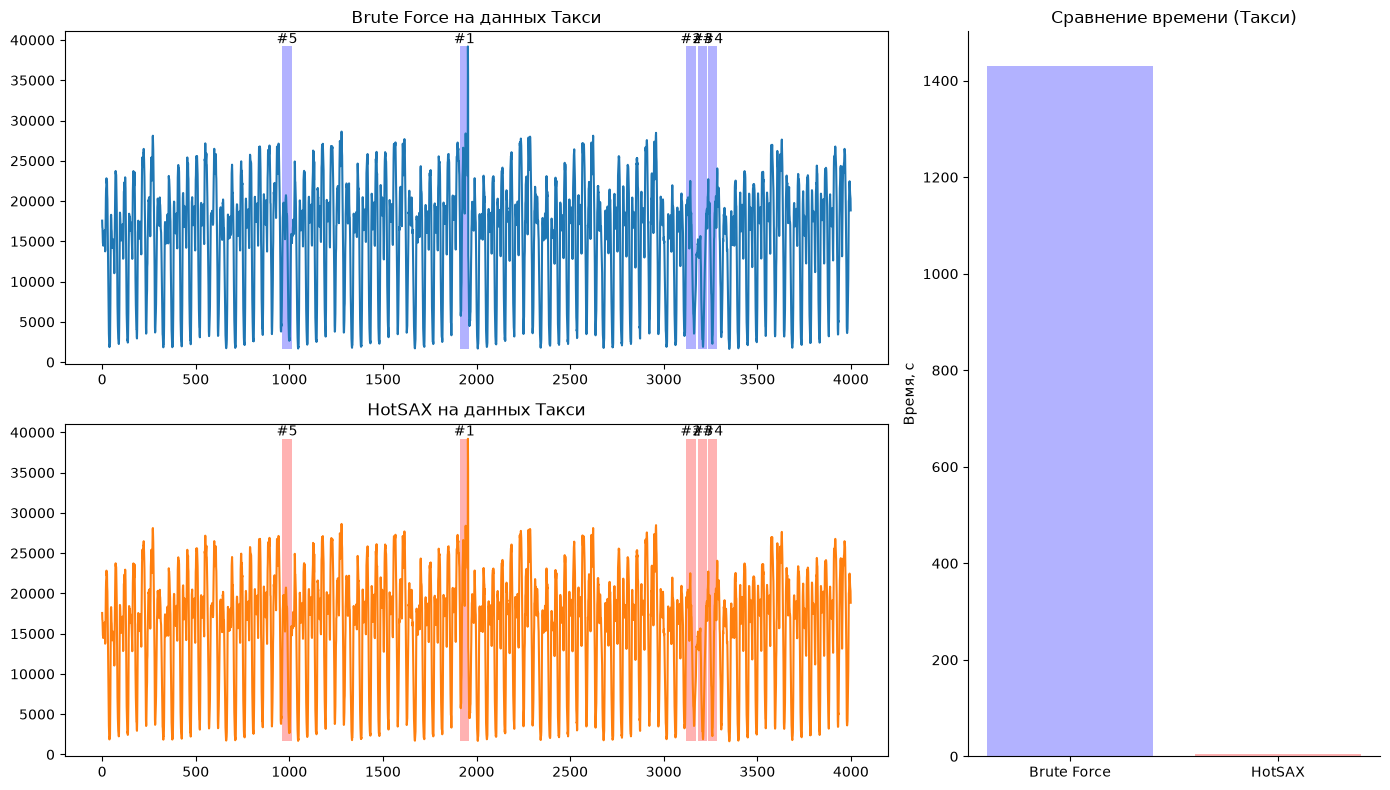

In [25]:
start_bf = time()
discords_taxi_bf = np.stack(find_discords_brute_force(nyc_taxi, 50, 5))
end_bf = time()
times['taxi_brute_force'] = end_bf - start_bf
print(f"Время brute force для такси: {times['taxi_brute_force']:.2f} секунд")

start_hs = time()
discords_taxi_hs = np.stack(find_discords_hotsax(nyc_taxi, win_size=50, num_discords=5))
end_hs = time()
times['taxi_hotsax'] = end_hs - start_hs
print(f"Время hotsax для такси: {times['taxi_hotsax']:.2f} секунд")


fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[2, 1]) 

ax_bf = fig.add_subplot(gs[0, 0]) 
ax_hs = fig.add_subplot(gs[1, 0]) 
ax_time = fig.add_subplot(gs[:, 1]) 


ax_bf.plot(nyc_taxi, color='tab:blue')
ax_bf.set_title('Brute Force на данных Такси')

for i, discord in enumerate(discords_taxi_bf):
    start_idx = int(discord[0])
    rect = Rectangle((start_idx, np.min(nyc_taxi)), 50, np.max(nyc_taxi) - np.min(nyc_taxi), 
                     facecolor='blue', alpha=0.3, edgecolor='none')
    ax_bf.add_patch(rect)
    ax_bf.text(start_idx + 25, np.max(nyc_taxi), f'#{i+1}', ha='center', va='bottom', fontsize=10)


ax_hs.plot(nyc_taxi, color='tab:orange')
ax_hs.set_title('HotSAX на данных Такси')

for i, discord in enumerate(discords_taxi_hs):
    start_idx = int(discord[0])
    rect = Rectangle((start_idx, np.min(nyc_taxi)), 50, np.max(nyc_taxi) - np.min(nyc_taxi), 
                     facecolor='red', alpha=0.3, edgecolor='none')
    ax_hs.add_patch(rect)
    ax_hs.text(start_idx + 25, np.max(nyc_taxi), f'#{i+1}', ha='center', va='bottom', fontsize=10)


algorithms = ['Brute Force', 'HotSAX']
execution_times = [times['taxi_brute_force'], times['taxi_hotsax']]

bars = ax_time.bar(algorithms, execution_times, color=['blue', 'red'], alpha=0.3)

ax_time.set_ylabel('Время, с')
ax_time.set_title('Сравнение времени (Такси)')
ax_time.spines['top'].set_visible(False)
ax_time.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

#### **3.2 Поиск диссонансов с помощью алгоритма DRAG**

In [7]:
!pip install stumpy==1.11.1


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import stumpy
from stumpy import core, config
from stumpy.scrump import _prescrump


e:\Data\SUSU\3rd_semester\TimeSeriesCourse\2026-Murzin-TimeSeriesCourse\.venv\Lib\site-packages\stumpy\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


Как мы помним из лекций:

**Диапазонный диссонанс** – подпоследовательность ряда, расстояние от которой до ее ближайшего соседа не ниже заданного порога. 

Основными параметрами при поисках диссонансов являются:
- $m$ - длина диссонанса
- $r$ - пороговое значение расстояния подпоследовательности ряда, до его ближайшего соседа


In [10]:
from modules.drag import find_candidates, DRAG


Для поиска диссонансов в данной части практической работы мы воспользуемся алгоритмом **DRAG (Discord Range Aware Gathering)**.
Для начала воспользуемся данным алгоритмом, чтобы найти диссонансы в наборе данных содержащем активность человека.

In [11]:
data = walk_run

Длину искомого диссонанса, как и для предыдущих алгоритмов, мы установим равно 50 точек.
Пороговое значение мы установим равным большим, чтобы узнать, как алгоритм отреагирует на большие значения данного параметра.

In [17]:
m = 50 
r = 10
idxs, _, _ = DRAG(data,m,r)
print(f'Колличество найденных диссонансов: {len(idxs)}')

Колличество найденных диссонансов: 0


Как вы можете видеть мы установили слишком большое пороговое значение, алгоритму не удалось выделить ни одного диссонанса. Попробуем уменьшить пороговое значение до 1, чтобы улучшить результат. 

In [18]:
m = 50 
r = 1
idxs, _, _ = DRAG(data, m, r)
print(f'Колличество найденных диссонансов: {len(idxs)}')

Колличество найденных диссонансов: 50


При такой комбинации параметров, улучшить ситуацию не получилось. Алгоритм выделил слишком большое количество диссонансов, часть которых является ложными диссонансами и не будут информативными для нас.

Произведите подобные эксперименты с набором данных такси NY. Постройте графики демонстрирующие найденные диссонансы. Пример Графика:
![second-graph](pics/fig_ex_2.png)

Колличество найденных диссонансов: 4


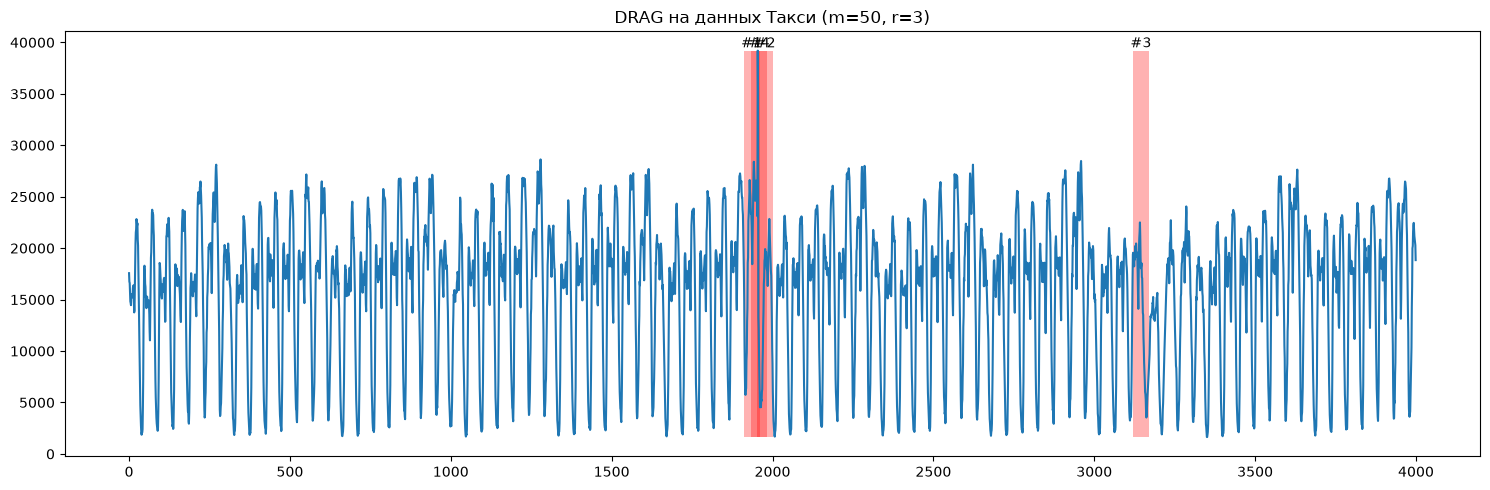

In [ ]:
# INSERT YOUR CODE

m_taxi = 50
r_taxi = 3

idxs_taxi, dists_taxi, nn_idxs_taxi = DRAG(nyc_taxi, m_taxi, r_taxi)
print(f'Количество найденных диссонансов: {len(idxs_taxi)}')

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(nyc_taxi, color='tab:blue')

for i, idx in enumerate(idxs_taxi):
    rect = Rectangle((idx, np.min(nyc_taxi)), m_taxi, np.max(nyc_taxi) - np.min(nyc_taxi),
                     facecolor='red', alpha=0.3, edgecolor='none')
    ax.add_patch(rect)
    ax.text(idx + m_taxi/2, np.max(nyc_taxi), f'#{i+1}', ha='center', va='bottom', fontsize=10)

ax.set_title(f'DRAG на данных Такси (m={m_taxi}, r={r_taxi})')
plt.tight_layout()
plt.show()

Чтобы разобраться, почему так происходит и как работает данный алгоритм, ниже мы реализуем все этапы алгоритма DRAG.

Как мы помним из лекций алгоритм DRAG содержит два этапа:

1. Отбор - За одно сканирование ряда сформировать множество кандидатов в диссонансы.
2. Очистка - За одно сканирование ряда отбросить кандидатов, которые являются ложными диссонансами.

##### 3.2.1 Отбор кандидатов

Первым этапом обработки данных является отбор множества потенциальных кандидатов. Мы выбираем из всего множества подпоследовательностей ряда такие, для которых расстояние до правых ближайших соседей больше параметра $r$.

In [33]:
#выбирем более реальное значение для порога
r = 3

In [34]:
T, M_T, Σ_T = core.preprocess(data, m)
#формируем массив длинной равной длине  исходного ряда - m + 1, 
#элемент массива является истинным, 
#в том случае если подпоследовательность является потенциальным кандидатом
is_cands = find_candidates(T, m, M_T, Σ_T, r, init_cands=None, right=True)
#находим индексы потенциальных кандидатов
cand_index = np.flatnonzero(is_cands)

In [35]:
print(f'{len(cand_index)} {len(cand_index)/len(data)*100} %')

113 11.3 %


Во время отбора кандидатов нам удалось выделить около 113 подпоследовательностей(около 11.3%), которые мы бы могли назвать потенциальными диссонансами.
Это большой процент, который не может нас устраивать как конечный результат.
Если посмотреть на рисунок ниже, мы увидим, что большая часть потенциальных диссонансов расположена в районе смены активности. 
К сожалению пресутсвуют и ложные диссонансы, которые случайным образом попали в данный список.

Сформируйте график найденных диссонансов

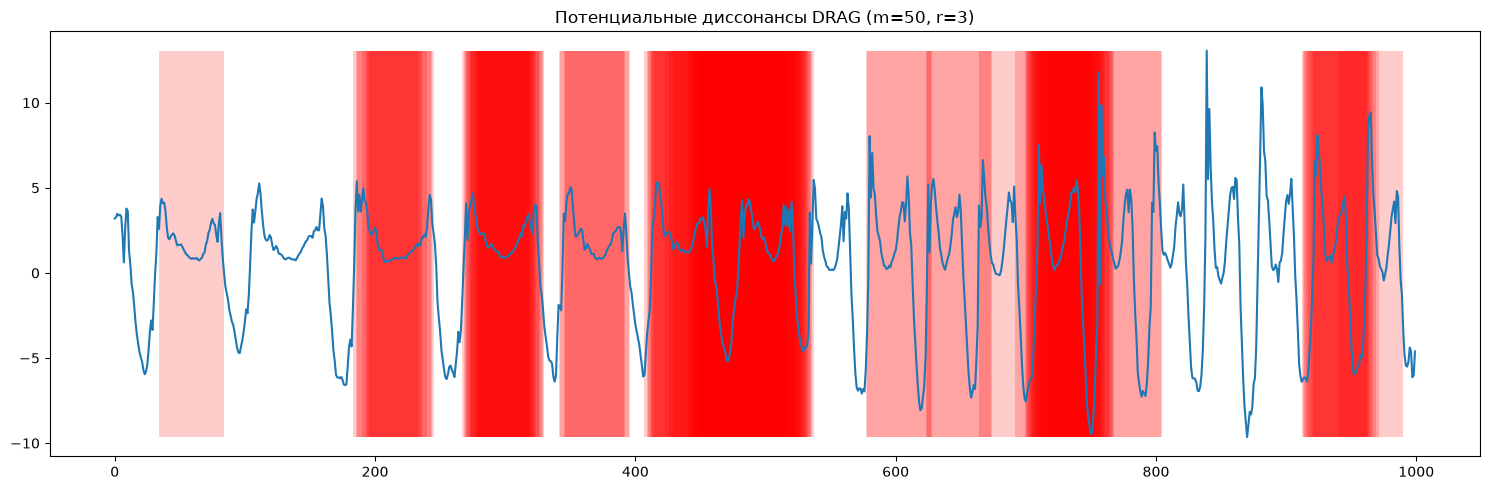

In [45]:
# INSERT YOUR CODE

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(data, color='tab:blue')

for idx in cand_index:
    rect = Rectangle((idx, np.min(data)), m, np.max(data) - np.min(data),
                     facecolor='red', alpha=0.2, edgecolor='none')
    ax.add_patch(rect)

ax.set_title(f'Потенциальные диссонансы DRAG (m={m}, r={r})')
plt.tight_layout()
plt.show()

##### 3.2.2 Очистка кандидатов
Как уже упоминалось выше, 11.3% слишком большой процент диссонансов.
Для уменьшения числа потенциальных кандидатов произведем очистку от ложных диссонансов, путем сравнения расстояния до левых ближайших соседей потенциальных диссонансов с порогом $r$.


In [39]:
is_cands = find_candidates(T, m, M_T, Σ_T, r, init_cands=is_cands, right=False)
cands = np.flatnonzero(is_cands)

In [40]:
len(cands)/len(data)*100

2.9000000000000004

Сформируйте график найденных диссонансов

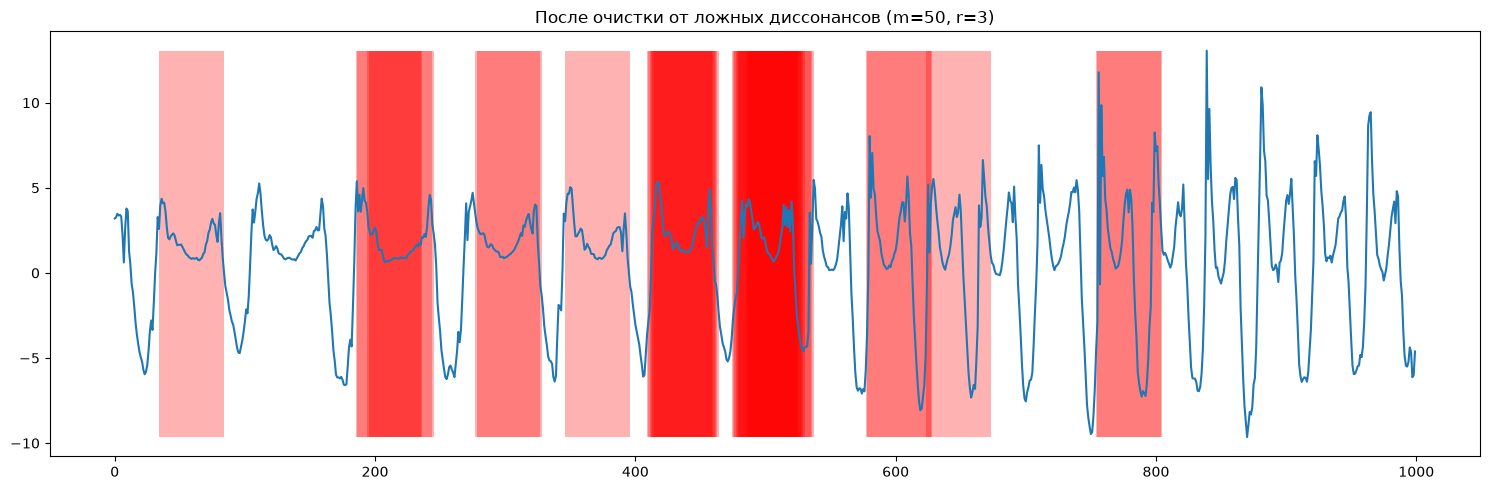

In [46]:
# INSERT YOUR CODE

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(data, color='tab:blue')

for idx in cands:
    rect = Rectangle((idx, np.min(data)), m, np.max(data) - np.min(data),
                     facecolor='red', alpha=0.3, edgecolor='none')
    ax.add_patch(rect)

ax.set_title(f'После очистки от ложных диссонансов (m={m}, r={r})')
plt.tight_layout()
plt.show()

Нам удалось сократить число диссонансов до 2.9%. Если проанализировать рисунок, то можно заметить, что большая их часть является тривиальными повторениями подпоследовательности в области смены активности. На следующем шаге избавимся от них.

In [43]:
from modules.drag import refine_candidates
discords_idx, discords_dist, discords_nn_idx = refine_candidates(T, m, M_T, Σ_T, is_cands)
len(discords_idx)/len(data)*100

0.8999999999999999

Сформируйте график найденных диссонансов

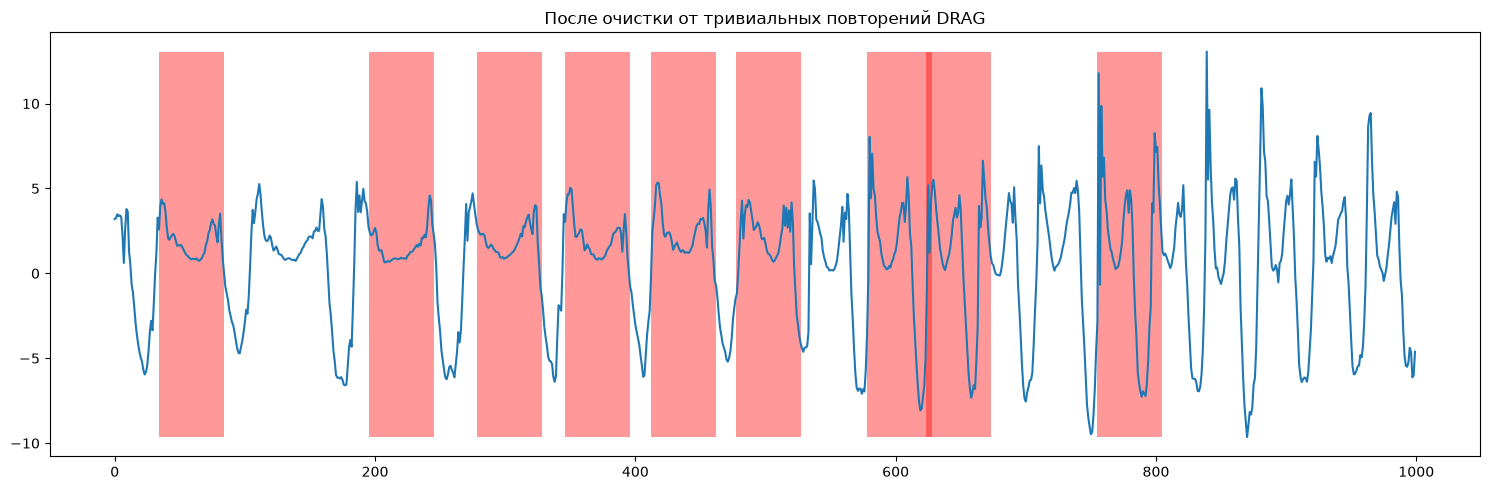

In [ ]:
# INSERT YOUR CODE

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(data, color='tab:blue')

for idx in discords_idx:
    rect = Rectangle((idx, np.min(data)), m, np.max(data) - np.min(data),
                     facecolor='red', alpha=0.4, edgecolor='none')
    ax.add_patch(rect)

ax.set_title('После очистки от тривиальных повторений DRAG')
plt.tight_layout()
plt.show()

##### 3.2.3 Подбор параметров

Реализуйте перебор параметров $m$ и $r$. Подберете параметры таким образом, чтобы алгоритм обнаружил только те диссонансы, которые связаны со сменой активности. Сделайте вывод о том, как эти параметры влияют на качество работы модели.
Подберите оптимальные параметры алгоритма для набора данных такси NY. 
Визуализируйте результаты для разных комбинаций. Сделайте выводы.


m=20, r=1 найдено диссонансов: 88
m=20, r=2 найдено диссонансов: 14
m=20, r=3 найдено диссонансов: 3
m=20, r=4 найдено диссонансов: 1
m=20, r=5 найдено диссонансов: 0
m=30, r=1 найдено диссонансов: 58
m=30, r=2 найдено диссонансов: 12
m=30, r=3 найдено диссонансов: 2
m=30, r=4 найдено диссонансов: 1
m=30, r=5 найдено диссонансов: 1
m=40, r=1 найдено диссонансов: 52
m=40, r=2 найдено диссонансов: 7
m=40, r=3 найдено диссонансов: 2
m=40, r=4 найдено диссонансов: 1
m=40, r=5 найдено диссонансов: 0
m=50, r=1 найдено диссонансов: 42
m=50, r=2 найдено диссонансов: 8
m=50, r=3 найдено диссонансов: 4
m=50, r=4 найдено диссонансов: 0
m=50, r=5 найдено диссонансов: 0
m=60, r=1 найдено диссонансов: 56
m=60, r=2 найдено диссонансов: 11
m=60, r=3 найдено диссонансов: 6
m=60, r=4 найдено диссонансов: 1
m=60, r=5 найдено диссонансов: 0


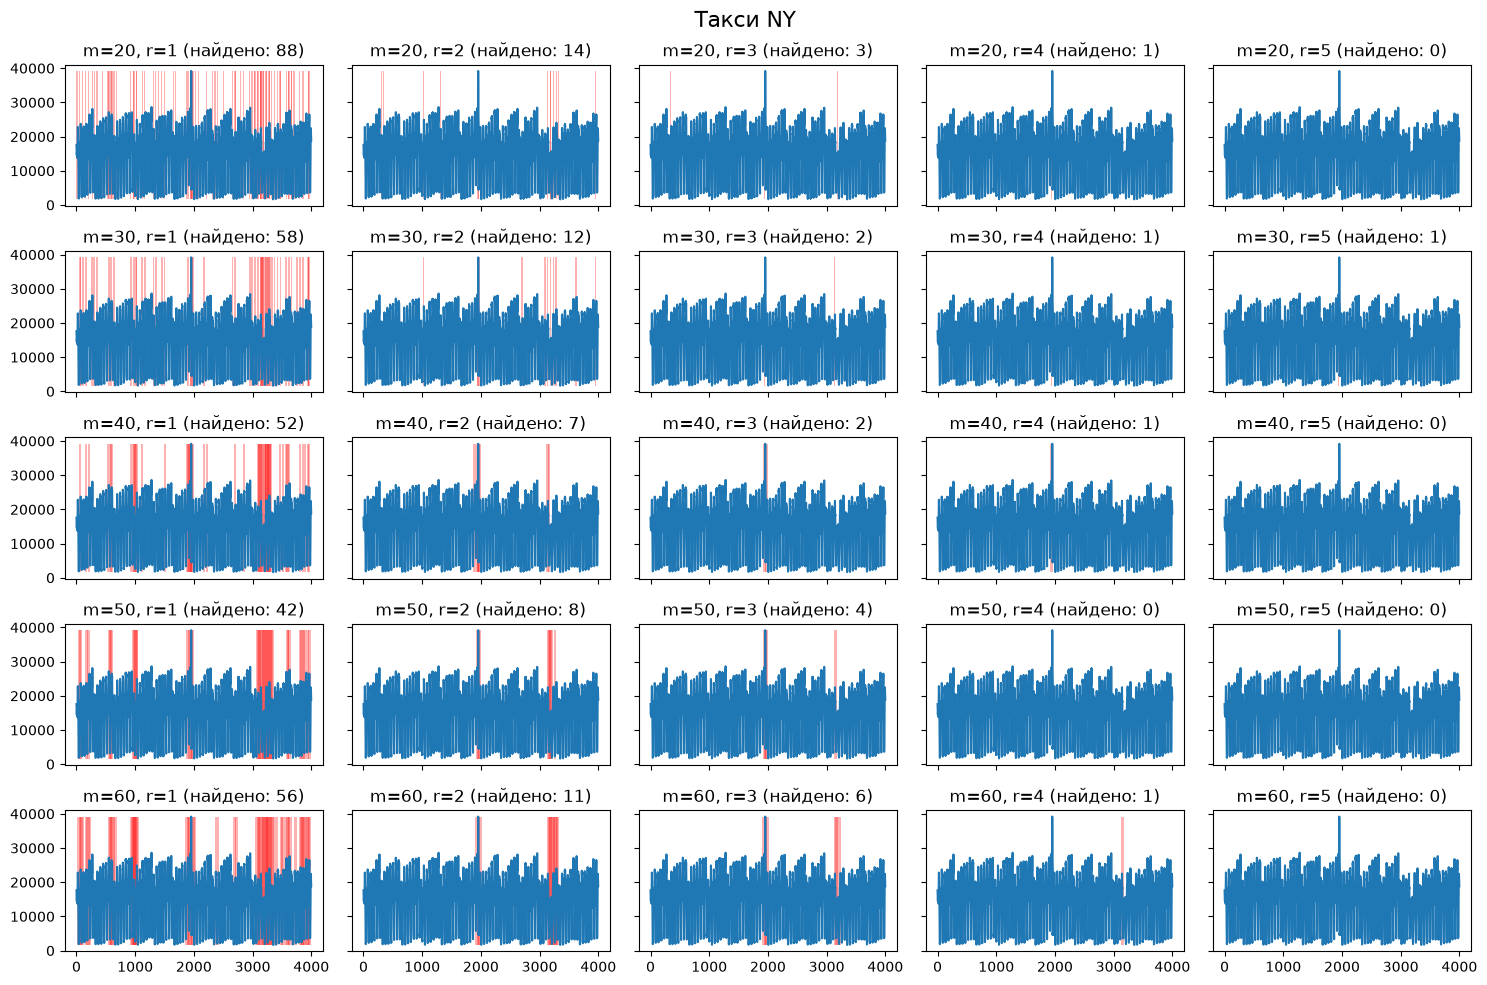

In [55]:
# INSERT YOUR CODE

m_values = [20, 30, 40, 50, 60]
r_values = [1, 2, 3, 4, 5]

fig, axes = plt.subplots(len(m_values), len(r_values), figsize=(15, 10), sharex=True, sharey=True)
fig.suptitle('Такси NY', fontsize=16)

for i, m_val in enumerate(m_values):
    for j, r_val in enumerate(r_values):
        idxs, _, _ = DRAG(nyc_taxi, m_val, r_val)
        count = len(idxs)
        
        print(f"m={m_val}, r={r_val} найдено диссонансов: {count}")
        
        ax = axes[i, j]
        ax.plot(nyc_taxi, color='tab:blue')
        ax.set_title(f'm={m_val}, r={r_val} (найдено: {count})')
        
        for idx in idxs:
            rect = Rectangle((idx, np.min(nyc_taxi)), m_val, np.max(nyc_taxi) - np.min(nyc_taxi),
                             facecolor='red', alpha=0.3, edgecolor='none')
            ax.add_patch(rect)

plt.tight_layout()
plt.show()

- При малых значениях порога r алгоритм находит много ложных диссонансов. При больших значениях алгоритм не находит ни одного диссонанса. Оптимальным является r равное 3 или 4, при котором алгоритм выделяет от 1 до 4 диссонансов.

- При малых значениях длины окна m алгоритм находит короткие всплески. При увеличении m, алгоритм находит более продолжительные изменения ряда. Оптимальным можно назвать m равное 50.

- Самый большой пик не был выделен алгоритмом DRAG. Он ищет подпоследовательности, расстояние до ближайшего соседа которых превышает заданный порог. Значит у данного пика есть похожие на него соседи в других частях ряда, и расстояние до них оказалось меньше порога. В то же время алгоритм Brute Force нашел этот пик, он ищет подпоследовательность с максимальным расстоянием до соседа, порог не задан.

#### **3.3 Поиск диссонансов с помощью алгоритма Merlin**

Как мы уже выяснили подбирать параметры для DRAG простым перебором не очень удобно. Для оптимизации данного процесса в статье [1] был предложен алгоритм Merlin для оптимального поиска подходящего порогового значения.

Условно мы можем разделить поиск диссонансов на три шага:

1. Поиск диссонансов минимальной длинны $minL$. На данном шаге $r = 2\sqrt{minL}$.
2. Поиск диссонансов следующих четырех длин. На данном шаге $r = 0.99 \cdot nndist_{m-1}$. Где $nndist_{m-1}$ - расстояние до ближайшего соседа предыдущего найденного диссонанса.
3. Поиск диссонансов всех 
оставшихся дли. $r = \mu - 2 \sigma$. Средние значение и стандартное отклонение вычисляются из расстояний 5 предыдущих диссонансов. н

[1] Nakamura T., Imamura M., Mercer R., Keogh E.J. MERLIN: parameter-free discovery of arbitrary length anomalies in massive time series archives. 20th IEEE Int. Conf. on Data Mining, ICDM 2020, Sorrento, Italy, November 17-20, 2020. pp. 1190-1195. IEEE (2020). https://doi.org/10.1109/ICDM50108.2020.00147

##### 3.3.1 Поиск диссонансов минимальной длинны

Вспомним последовательность действий первого шага алгоритма:
![merlin-part-first](pics/first_part.png)

В данной работе мы внесем небольшое изменение, мы будем считать, что подпоследовательность может быть диссонансом только в том случае, если больше 75% точек, не входят в состав других диссонансов. 

In [70]:
T = walk_run
m = 50
# сформируем массив метод для потенциальных кандидатов в диссонансы.
# после каждого найденного диссонанса, 
# мы будем исключать окружающие его подпоследовательности из числа потенциальных кандидатов,
# путем замены значений их меток на false
excl_zone = int(np.ceil(m / 4))
include = np.ones(len(T)-m+1, dtype=bool)
# Количество диссонансов, которые мы будем искать
topK = 10


In [71]:
dis_idx = -np.ones((topK))
dis_nnDist = -np.ones((topK))
dis_nn_idx = np.full((topK),-np.inf)
#первое прближение r
r = 2*np.sqrt(m)
minL = m
maxL = int(m+np.ceil(m*0.1))
#количество найденных диссонасов
cound_find_dis = 0

while dis_nnDist[cound_find_dis-1]<0 and cound_find_dis<topK:
    result = DRAG(data=T,m=minL,r=r, include =include)
    for diss, nnDist, nn in zip(*result):
        dis_idx[cound_find_dis] = diss
        dis_nnDist[cound_find_dis] = nnDist
        dis_nn_idx[cound_find_dis] = nn
        #исключаем окружающие найденный диссонас 
        #подпоследовательности и числа потенциальных диссонасов
        core.apply_exclusion_zone(include, diss, excl_zone, False)
        cound_find_dis+=1
        if cound_find_dis>=topK:
            break
    r*=0.5

In [72]:
maxL

55

In [73]:
print('Количество найденных на первом этапе диссонансов:', cound_find_dis)

Количество найденных на первом этапе диссонансов: 2


На первом шаге нам удалось выделить 2 диссонанса из 10 требуемых. 
Реализуйте, оставшиеся шаги алгоритма, чтобы найти оставшиеся диссонансы. 

![merlin-part-first](pics/second_part.png)


In [74]:
# Этап 2: поиск диссонансов следующих четырёх длин (шаги 5-10)
# r = 0.99 * nnDist предыдущего найденного диссонанса

for i in range(minL + 1, minL + 5):
    nnDist_i = -np.inf

    # Если ещё есть место для новых диссонансов — задаём начальный r
    if cound_find_dis < topK:
        r = 0.99 * dis_nnDist[cound_find_dis - 1]

    while nnDist_i < 0 and cound_find_dis < topK:
        result = DRAG(data=T, m=i, r=r, include=include)
        D_i = []
        for diss, nnDist, nn in zip(*result):
            if cound_find_dis >= topK:
                break
            dis_idx[cound_find_dis] = diss
            dis_nnDist[cound_find_dis] = nnDist
            dis_nn_idx[cound_find_dis] = nn
            D_i.append(nnDist)
            # исключаем окружающие подпоследовательности
            core.apply_exclusion_zone(include, diss, excl_zone, False)
            cound_find_dis += 1

        # nnDist_i — минимальное расстояние среди найденных на этой длине
        if len(D_i) > 0:
            nnDist_i = np.min(D_i)
        else:
            nnDist_i = -np.inf

        r = 0.99 * r

# Этап 3: поиск диссонансов всех оставшихся длин (шаги 11-17)
# r = mu - 2*sigma по 5 предыдущим nnDist

for i in range(minL + 5, maxL + 1):
    if cound_find_dis >= topK:
        break

    # берём 5 предыдущих значений nnDist (гарантированно существуют, т.к. i >= minL+5)
    prev_nnDist = dis_nnDist[cound_find_dis - 5:cound_find_dis]
    mu = np.mean(prev_nnDist)
    sigma = np.std(prev_nnDist)
    r = mu - 2 * sigma

    result = DRAG(data=T, m=i, r=r, include=include)
    D_i = []
    for diss, nnDist, nn in zip(*result):
        if cound_find_dis >= topK:
            break
        dis_idx[cound_find_dis] = diss
        dis_nnDist[cound_find_dis] = nnDist
        dis_nn_idx[cound_find_dis] = nn
        D_i.append(nnDist)
        core.apply_exclusion_zone(include, diss, excl_zone, False)
        cound_find_dis += 1

    nnDist_i = np.min(D_i) if len(D_i) > 0 else -np.inf

    # добираем диссонансы на этой длине, пока nnDist_i < 0 и есть место
    while nnDist_i < 0 and cound_find_dis < topK:
        result = DRAG(data=T, m=i, r=r, include=include)
        D_i = []
        for diss, nnDist, nn in zip(*result):
            if cound_find_dis >= topK:
                break
            dis_idx[cound_find_dis] = diss
            dis_nnDist[cound_find_dis] = nnDist
            dis_nn_idx[cound_find_dis] = nn
            D_i.append(nnDist)
            core.apply_exclusion_zone(include, diss, excl_zone, False)
            cound_find_dis += 1

        nnDist_i = np.min(D_i) if len(D_i) > 0 else -np.inf
        r = r - sigma

print('Всего найдено диссонансов:', cound_find_dis)

Всего найдено диссонансов: 9


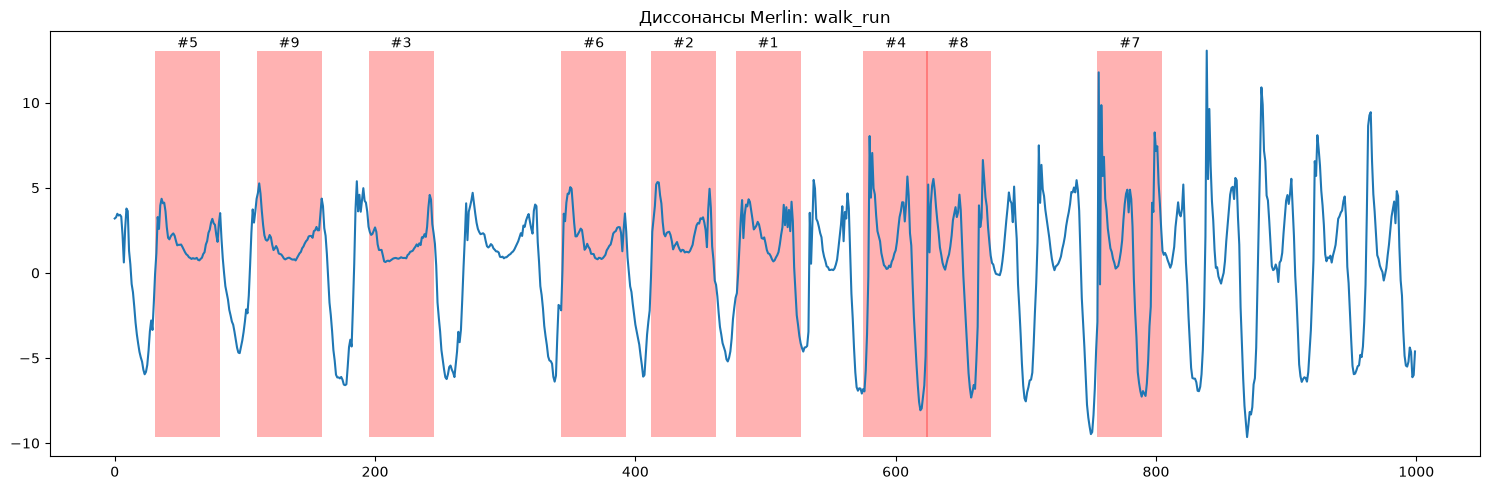

In [75]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(walk_run, color='tab:blue')
ax.set_title('Диссонансы Merlin: walk_run')

for i in range(cound_find_dis):
    if dis_idx[i] < 0: 
        break
    rect = Rectangle((dis_idx[i], np.min(walk_run)), 50, np.max(walk_run) - np.min(walk_run),
                     facecolor='red', alpha=0.3, edgecolor='none')
    ax.add_patch(rect)
    ax.text(dis_idx[i] + 25, np.max(walk_run), f'#{i+1}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

Найдите диссонансы набора такси NY. Визуализируйте найденные диссонансы для обоих наборов данных, сравните с результатами остальных методов. 


In [76]:
# INSERT YOUR CODE

T = nyc_taxi
m = 50

excl_zone = int(np.ceil(m / 4))
include = np.ones(len(T) - m + 1, dtype=bool)

topK = 10

dis_idx = -np.ones((topK))
dis_nnDist = -np.ones((topK))
dis_nn_idx = np.full((topK), -np.inf)

# первое приближение r
r = 2 * np.sqrt(m)
minL = m
maxL = int(m + np.ceil(m * 0.1))

# количество найденных диссонансов
cound_find_dis = 0

# Этап 1: поиск диссонансов минимальной длины
while dis_nnDist[cound_find_dis - 1] < 0 and cound_find_dis < topK:
    result = DRAG(data=T, m=minL, r=r, include=include)
    for diss, nnDist, nn in zip(*result):
        dis_idx[cound_find_dis] = diss
        dis_nnDist[cound_find_dis] = nnDist
        dis_nn_idx[cound_find_dis] = nn
        core.apply_exclusion_zone(include, diss, excl_zone, False)
        cound_find_dis += 1
        if cound_find_dis >= topK:
            break
    r *= 0.5

print('Количество найденных на первом этапе диссонансов:', cound_find_dis)

# Этап 2: поиск диссонансов следующих четырёх длин (шаги 5-10)
for i in range(minL + 1, minL + 5):
    nnDist_i = -np.inf

    if cound_find_dis < topK:
        r = 0.99 * dis_nnDist[cound_find_dis - 1]

    while nnDist_i < 0 and cound_find_dis < topK:
        result = DRAG(data=T, m=i, r=r, include=include)
        D_i = []
        for diss, nnDist, nn in zip(*result):
            if cound_find_dis >= topK:
                break
            dis_idx[cound_find_dis] = diss
            dis_nnDist[cound_find_dis] = nnDist
            dis_nn_idx[cound_find_dis] = nn
            D_i.append(nnDist)
            core.apply_exclusion_zone(include, diss, excl_zone, False)
            cound_find_dis += 1

        nnDist_i = np.min(D_i) if len(D_i) > 0 else -np.inf
        r = 0.99 * r

# Этап 3: поиск диссонансов всех оставшихся длин (шаги 11-17)
for i in range(minL + 5, maxL + 1):
    if cound_find_dis >= topK:
        break

    prev_nnDist = dis_nnDist[cound_find_dis - 5:cound_find_dis]
    mu = np.mean(prev_nnDist)
    sigma = np.std(prev_nnDist)
    r = mu - 2 * sigma

    result = DRAG(data=T, m=i, r=r, include=include)
    D_i = []
    for diss, nnDist, nn in zip(*result):
        if cound_find_dis >= topK:
            break
        dis_idx[cound_find_dis] = diss
        dis_nnDist[cound_find_dis] = nnDist
        dis_nn_idx[cound_find_dis] = nn
        D_i.append(nnDist)
        core.apply_exclusion_zone(include, diss, excl_zone, False)
        cound_find_dis += 1

    nnDist_i = np.min(D_i) if len(D_i) > 0 else -np.inf

    while nnDist_i < 0 and cound_find_dis < topK:
        result = DRAG(data=T, m=i, r=r, include=include)
        D_i = []
        for diss, nnDist, nn in zip(*result):
            if cound_find_dis >= topK:
                break
            dis_idx[cound_find_dis] = diss
            dis_nnDist[cound_find_dis] = nnDist
            dis_nn_idx[cound_find_dis] = nn
            D_i.append(nnDist)
            core.apply_exclusion_zone(include, diss, excl_zone, False)
            cound_find_dis += 1

        nnDist_i = np.min(D_i) if len(D_i) > 0 else -np.inf
        r = r - sigma

print('Всего найдено диссонансов:', cound_find_dis)

Количество найденных на первом этапе диссонансов: 10
Всего найдено диссонансов: 10


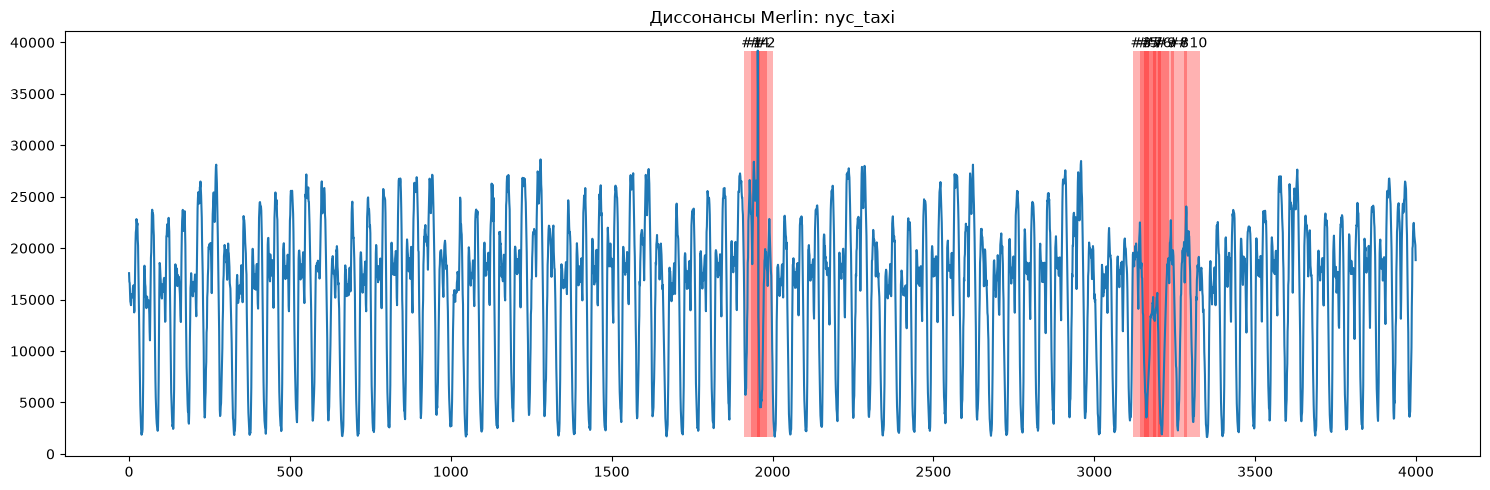

In [77]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(nyc_taxi, color='tab:blue')
ax.set_title('Диссонансы Merlin: nyc_taxi')

for i in range(cound_find_dis):
    if dis_idx[i] < 0:
        break
    rect = Rectangle((dis_idx[i], np.min(nyc_taxi)), 50, np.max(nyc_taxi) - np.min(nyc_taxi),
                     facecolor='red', alpha=0.3, edgecolor='none')
    ax.add_patch(rect)
    ax.text(dis_idx[i] + 25, np.max(nyc_taxi), f'#{i+1}', ha='center', va='bottom')

plt.tight_layout()
plt.show()